# 선택: 학습 시작 ⏱️

아래 셀은 처음에만 시작을 기록해요. 재실행·재시작하면 이전 기록을 보여줘요. 쉬는 시간도 포함해요. 타이머는 선택이에요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day21-xy-coordinates")
    if p.name == "day21-xy-coordinates"
    and p.is_dir()
    and (p / "day21.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day21.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day21 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day21_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        _timer["action"]("start")

# Day21 | 바닥 위 위치와 움직임을 좌표로 읽어요

2026-11-09 · Physical AI · 실제 약 60분 잠정 목표

Day20에서 시간과 벽까지 거리를 그래프로 만들고 저장했어요. 오늘은 한 걸음 더 나아가 **가상 로봇이 바닥 위 어디에 있는지** 두 숫자로 나타내요. 위치를 읽고, 이동 전·후를 계산하고, 직접 경로를 그려요. 숫자는 시뮬레이션이며 실제 센서 측정이 아니에요. 정답과 해설은 헴이 시도한 뒤 함께 확인해요.

**선택 타이머:** ① 맨 위 시작 셀 실행 → ② 문제 풀기 → ③ 맨 아래 종료 셀 실행 후 `종료` 입력 → ④ Ctrl+S로 노트북 저장 → ⑤ 이 대화에 ‘다 풀었어’라고 알려주기. 타이머를 쓰지 않아도 풀 수 있어요. 쉬거나 노트북을 닫은 시간도 포함해요. 종료 셀의 시각은 저장과 채팅 발송 시각이 아니며, 노트북은 메시지 발송을 감지하지 못해요. ‘모두 실행’ 중에는 `종료`를 입력하지 마세요.

잠정 순서: 그림 10분, 위치와 이동 15분, 직접 구현 15분, 조건 변경·오류 찾기 15분, 정리 5분. 실제 소요 시간은 달라질 수 있어요. 막힌 곳과 실제 시간을 알려주면 다음 분량을 조절할게요.


## 시작 확인 | 그림부터 또는 실습부터

![원점 O와 x·y 양의 방향, 예시 시작 S와 끝 E, 이동 화살표](assets/01-xy-example.png)

그림의 S와 E는 오늘 문제와 다른 **예시**예요. 아직 답하지 않은 새 미리보기는 없으며, Day20의 시간·거리 입력
순서는 이미 함께 확인했어요.


### 확인 문제 Q1 · 필수: 한 점 읽기

**볼 자료:** 위 그림의 예시 시작점 S `(1, 1)`과 끝점 E `(3, 2)`예요. 숫자의 단위는 m(미터)이고 첫 숫자는 x, 두 번째는 y예요.

**할 일:** E에서 x 위치와 y 위치를 각각 적고, 그림에서 S에서 E로 향하는 화살표가 나타내는 것을 적어요.

**답할 곳:** 바로 아래 `Q1 답안` Markdown 셀. 코드를 수정하지 않아요.


**Q1 답안:**

- E의 x 위치 3 m / y 위치 2 m.
- 화살표의 뜻: 이동.
- 내 선택: 그림부터 / 바로 실습부터.


그림부터는 다음 개념과 예제를 천천히 읽어요. 바로 실습부터는 예제를 실행한 뒤 필요한 설명으로 돌아와요. 둘 다 필수 Q1~Q7을 풀어요.


## 개념 | 시간 그래프와 바닥 위치의 차이

**쉬운 뜻:** 바닥에서 어느 곳에 있는지 가로와 세로 두 숫자로 적어요.

**비유:** 바둑판의 기준 칸에서 오른쪽과 위쪽으로 떨어진 위치를 찾는 것과 비슷해요.

**실제 용어:** `(x, y)`는 2차원 좌표, O `(0, 0)`은 원점이에요. 첫 숫자는 x 위치(m), 두 번째는 y 위치(m)예요. x의 양의 방향은 오른쪽, y의 양의 방향은 위쪽이에요.

![좌표평면 원점과 양의 x·y 방향, 시작 S와 끝 E](assets/01-xy-example.png)

Day20 시간–거리 그래프의 x축은 시간(초)이었어요. **오늘 그림의 x축은 바닥의 x 위치(m)**예요. 글자가 둘 다 x여도 뜻과 단위가 달라요. 위 S `(1,1)`은 원점에서 오른쪽 1m, 위쪽 1m에 있어요. E `(3,2)`는 오른쪽 3m, 위쪽 2m예요.


### 확인 문제 Q2 · 필수: 축의 의미 비교

**볼 자료:** Day20 Q4에서 A와 B를 함께 그린 시간–거리 그래프와 위 바닥 위치 그림이에요. <br/>
**할 일:** 두 그림에서 각각 가로축이 무엇이고 단위가 무엇인지 적어요.<br/>
**답할 곳:** 아래 Markdown 빈칸. 코드는 수정하지 않아요.<br/>


**Q2 답안:** <br/>

- Day20 가로축 시간, 단위 s.
- 오늘 가로축 위치, 단위 m.
- 서로 다른 점: 기준.


## 예제 | 이동 전과 이동 후 짝짓기

![예시 S(1,1)에서 E(3,2)로 향하는 화살표](assets/01-xy-example.png)

**쉬운 뜻:** 새 위치에서 이전 위치를 빼면 위치가 얼마나 바뀌었는지 알 수 있어요.

**비유:** 바둑판에서 출발 칸과 도착 칸을 비교해 오른쪽과 위로 각각 몇 칸 움직였는지 세어요.

**실제 용어:** 이 차이를 위치 변화량 `(Δx, Δy)`이라고 해요. Δ는 ‘바뀐 양’이라는 뜻이에요.

예시의 이동 전 S는 `(1, 1)` m, 이동 후 E는 `(3, 2)` m예요.

1. x 변화량 = 이동 후 x − 이동 전 x = `3 − 1 = 2` m.
2. y 변화량 = 이동 후 y − 이동 전 y = `2 − 1 = 1` m.
3. 따라서 이 예시의 변화량은 `(2, 1)` m예요. 위치 `(3,2)`와 변화량 `(2,1)`은 다른 뜻이에요.

이것은 예시의 답이며 아래의 새 숫자 문제의 답이 아니에요. 음수 변화량은 이 그림의 양의 방향과 반대 방향이에요.


### 확인 문제 Q3 · 필수: 새 이동 계산

**주어진 값:** 이동 전 P `(2, 1)` m, 이동 후 Q `(4, 3)` m예요.

- **할 일:** Q는 이동 **후** 위치예요. 이동 후에서 이동 전을 빼어 x·y 변화량을 각각 계산하고 한 쌍으로 적어요. P와 Q 중 어느 것이 이동 전인지도 적어요.

- **답할 곳:** 아래 Markdown 빈칸. 코드는 수정하지 않아요.


**Q3 답안:**

- 이동 전 (2, 1), 이동 후 점 (4, 3).
- x 변화량 4 - 2 = 2m.
- y 변화량 3 - 1 = 2m.
- 변화량 `( 2, 2 )` m.


## 직접 구현 | 이동 전과 후를 계산하기

![예시 좌표평면: S는 이동 전, E는 이동 후](assets/01-xy-example.png)


### 확인 문제 Q4 · 필수: 함수 완성

**할 일:** 바로 아래 `Q4 코드` 셀의 `...` 두 곳을 채워요. `move_xy`는 이동 전 위치 `(x_m, y_m)`에 x·y 변화량 `(dx_m, dy_m)`을 각각 더해 **이동 후 위치**를 `(새 x, 새 y)` 순서의 튜플로 반환해요. 입력값과 반환값의 단위는 모두 m예요. 제공된 두 호출을 실행하고 두 결과를 아래 답안에 옮겨 적어요. 예제 함수가 아닌 이 셀만 수정하세요.


In [ ]:
def move_xy(x_m, y_m, dx_m, dy_m):
    # x_m, y_m: 이동 전 바닥 위치(m)
    # dx_m, dy_m: 이번 이동에서 x와 y가 바뀌는 양(m)
    next_x_m = dx_m + x_m  # 이동 후 x 위치(m)
    next_y_m = dy_m + y_m  # 이동 후 y 위치(m)
    return (next_x_m, next_y_m)  # 이동 후 위치를 x, y 순서로 반환


print("실험 A:", move_xy(0, 0, 2, 1))
print("실험 B:", move_xy(3, 2, -1, 1))

실험 A: (2, 1)
실험 B: (2, 3)


**Q4 답안:**

- 실험 A의 이동 후 위치(2, 1) m.
- 실험 B의 이동 후 위치(2, 3) m.
- B의 `-1`이 뜻하는 방향: x 위치를 한칸 아래로.


## 조건 변화 | 그래프로 경로 그리기

![예시의 x·y 위치 축, 원점, S와 E의 좌표 및 화살표](assets/01-xy-example.png)


### 확인 문제 Q5 · 필수: 순서대로 두 번 이동

**주어진 값:** 시작 위치 `(0, 0)` m. 첫 이동의 변화량 `(1, 2)` m, 두 번째 이동의 변화량 `(2, -1)` m.

**할 일:** 첫 이동 **후** 위치를 Q4 함수로 구하고, 그 결과를 두 번째 이동의 **전** 위치로 사용해 최종 위치를 구하세요. 아래 `Q5 코드` 셀의 `...`을 채워 출력하세요.

**답할 곳:** 코드 셀과 바로 아래 Markdown 빈칸. Q4 함수가 실행된 상태에서 이 셀을 실행해요.


In [ ]:
first_xy = move_xy(0, 0, 1, 2)  # 첫 이동 후 위치(m)
end_xy = move_xy(1, 2, 2, -1)  # 첫 이동 후 x, y가 두 번째 이동 전 위치예요
print("첫 이동 후:", first_xy, "두 번째 이동 후:", end_xy)

첫 이동 후: (1, 2) 두 번째 이동 후: (3, 1)


**Q5 답안:**

- 첫 이동 후 (1, 2) m
- 두 번째 이동 후 (3, 1) m.
- 두 번째 이동 전 위치로 첫 결과를 쓰는 이유: 이동전 후 차이를 찾아야 하므로.


### 확인 문제 Q6 · 필수: 경로 그림 직접 만들기

**볼 자료:** Q5의 시작 위치, 첫 이동 후 위치, 두 번째 이동 후 위치예요.

**할 일:** 아래 `Q6 코드` 셀에 세 위치의 x 목록과 y 목록을 같은 이동 순서로 넣고, `ax.plot`의 첫째 인자에 x 목록, 둘째 인자에 y 목록을 넣어요. 제목·축 단위·점 표시·눈금과 동일한 x/y 길이 비율을 확인하고 실행하세요. 끝 위치를 아래에 적어요.

**답할 곳:** 이 코드 셀과 아래 Markdown 빈칸.


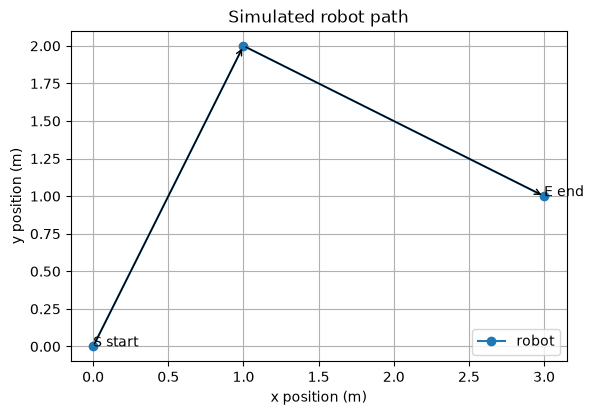

In [ ]:
import matplotlib.pyplot as plt  # Day20에서 사용한 그래프 도구

xs_m = [0, 1, 3]
ys_m = [0, 2, 1]  # 같은 순서의 y 위치(m)
fig, ax = plt.subplots()  # 그림 전체와 그릴 영역
ax.plot(xs_m, ys_m, marker="o", label="robot")  # x 위치 목록, y 위치 목록
ax.set_xlabel("x position (m)")
ax.set_ylabel("y position (m)")
ax.set_title("Simulated robot path")
ax.grid(True)
ax.legend()
ax.annotate("S start", (xs_m[0], ys_m[0]))  # 입력 목록의 첫 위치: 출발점
ax.annotate("E end", (xs_m[-1], ys_m[-1]))  # 입력 목록의 마지막 위치: 도착점
for i in range(1, len(xs_m)):  # 각 이전 위치에서 다음 위치로 화살표를 그려요
    ax.annotate(
        "",
        xy=(xs_m[i], ys_m[i]),
        xytext=(xs_m[i - 1], ys_m[i - 1]),
        arrowprops={"arrowstyle": "->"},
    )
ax.set_aspect("equal", adjustable="box")  # x와 y의 1m를 같은 화면 길이로 표시
plt.show()

**Q6 답안:**

- 입력 목록의 **마지막** 점은 `(3, 1)` m.
- 같은 순서의 x와 y를 묶는 이유: 좌표에 표시해야하니까?.


## 디버깅과 이해 확인

![이동 전 S(1,1), 이동 후 E(3,2)와 방향 화살표가 있는 예시 그림](assets/01-xy-example.png)


### 확인 문제 Q7 · 필수: 잘못 더한 값을 고쳐요

**주어진 값:** 이동 전 위치 `(2, 3)` m, 변화량 `(1, -2)` m. 아래 `Q7 코드`는 y 변화량 대신 x 변화량을 y에 더하고 있어요.

**할 일:** `wrong_next_y_m`을 계산하는 **한 줄만** 고쳐서 이동 후 y를 구하세요. x 관련 줄은 바꾸지 않아요. 실행 결과의 이동 후 `(x, y)`와 무엇을 왜 바꿨는지 아래에 적어요.

**답할 곳:** 아래 코드 셀과 Markdown 빈칸.


In [ ]:
x_m, y_m = 3, 2  # 이동 전 위치(m)
dx_m, dy_m = 2, 1  # 각각 x와 y의 변화량(m)
next_x_m = x_m + dx_m  # 올바른 이동 후 x(m), 수정하지 않아요
wrong_next_y_m = y_m + dy_m  # 이 한 줄에서 더하는 값만 고쳐요
print("이동 후 위치:", (next_x_m, wrong_next_y_m))

이동 후 위치: (5, 3)


**Q7 답안:** 더한 값 dx_m를 dy_m로 바꿨다. 이동 후 위치 `( 5, 3 )` m. 이유: 축끼리 맞춰야해서.


### 필수 이해 확인

**할 일:** 위치와 위치 변화량의 차이를 친구에게 두 문장 이내로 설명하세요. 오늘 막힌 곳을 하나 적고 없으면 `없음`이라고 써요.

**답할 곳:** 바로 아래 Markdown 빈칸.


- 내 설명: 위치는 좌표고 변화량의 차이는 다음 위치가 어느정도 변할지 알게해주는거
- 막힌 부분: \_\_\_
- 자기 평가 하나 선택: 혼자 설명할 수 있음 / 교재를 보면 설명할 수 있음 / 같이 다시 보고 싶음


### 선택 문제 · 하지 않아도 완료돼요

Q5의 두 번째 이동 변화량만 `(0, -1)` m로 바꾸면 이동 후 위치가 어떻게 달라질지 예상하고 Q4 함수로 확인해요.

**기대 결과:** 예상 위치와 확인 결과, 짧은 이유 한 줄.

**답할 곳:** 아래 Markdown 빈칸. 필수 제출에는 포함하지 않아요.


In [ ]:
print(move_xy(0, 0, 0, -1))

(0, -1)


- 예상 x축은 그대로 y축은 한칸 아래로
- 확인 (0, -1)
- 이유 다음 움직일 정도를 넣어주니까


**제출:** 필수 Q1~Q7 답안과 코드·그래프를 노트북에 저장하고 이 대화에 ‘다 풀었어’라고 알려주세요. 실제 걸린 시간과 막힌 곳도 알려주면 다음 분량을 조정할게요. 다 못 풀었으면 멈춘 곳만 알려줘도 괜찮아요.


**선택: 새로 측정하기** 정말 다시 잴 때만 노트북 초기화 셀의 `enabled = False`를 `True`로 바꾸고 실행한 뒤 `초기화`를 직접 입력해요. 이전 기록은 백업돼요. 그다음 맨 위 시작 셀을 다시 실행해요. 일반 실행이나 모두 실행만으로는 초기화되지 않아요.


## 선택: 새로 측정하기

다시 측정할 때만 아래 False를 True로 바꾸고 실행한 뒤 `초기화`를 입력해요. 기존 기록을 백업한 후 시작 셀을 다시 실행해요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day21-xy-coordinates")
    if p.name == "day21-xy-coordinates"
    and p.is_dir()
    and (p / "day21.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day21.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day21 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day21_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        enabled = False  # 다시 측정할 때만 True로 바꾸세요
        if enabled:
            _timer["action"]("reset", input("초기화하려면 초기화 입력: "), enabled=True)
        else:
            print("초기화는 비활성화되어 있어요.")

## 선택: 학습 종료 ⏱️

완료할 때 아래 셀을 실행하고 직접 `종료`를 입력해요. 빈 입력은 취소예요. 모두 실행 중에는 종료를 입력하지 마세요. 종료 뒤 Ctrl+S로 저장하고 이 대화에 알려주세요. 종료 시각은 저장·메시지 시각과 달라요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day21-xy-coordinates")
    if p.name == "day21-xy-coordinates"
    and p.is_dir()
    and (p / "day21.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day21.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day21 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day21_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        _timer["finish_interactive"]()